## 01 · 분류 모델 준비와 정확도
교재 **210–211쪽**

In [1]:
# --- 실습 준비: 8-2절 모델 다시 만들기 ---
# 필요한 라이브러리를 모두 불러옵니다.
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score # 정확도 계산을 위해 불러옵니다.

# 1. 데이터를 불러오고 타깃 변수를 생성합니다.
df = pd.read_csv("Part4 Chapter8 Wine Quality.csv")
df['good_quality'] = (df['quality'] >= 7).astype(int)

# 2. 피처(X)와 타깃(y)을 정의하고 데이터를 분할합니다.
X = df.drop(columns=['quality', 'good_quality'])
y = df['good_quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. 데이터를 스케일링합니다.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. 모델을 학습시키고 예측을 수행합니다.
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_test_scaled)

# --- 실습 준비 끝 ---
# accuracy_score 함수에 실제 정답(y_test)과 모델의 예측(predictions)을 전달하여 정확도를 계산합니다.
accuracy = accuracy_score(y_test, predictions)
print(f"모델의 정확도: {accuracy:.4f}")

모델의 정확도: 0.9083


## 02 · 오차 행렬
교재 **212쪽**

In [2]:
# 오차 행렬 계산을 위해 라이브러리를 불러옵니다.
from sklearn.metrics import confusion_matrix

# confusion_matrix 함수에 실제 정답(y_test)과 모델의 예측(predictions)을 전달합니다.
cm = confusion_matrix(y_test, predictions)
print("오차 행렬:")
print(cm)

오차 행렬:
[[193   8]
 [ 13  15]]


## 03 · 정밀도·재현율·F1 스코어
교재 **214쪽**

In [3]:
# 정밀도, 재현율, F1 스코어 계산을 위해 라이브러리를 불러옵니다.
from sklearn.metrics import precision_score, recall_score, f1_score

# 각 평가 지표를 계산합니다.
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)
print(f"정밀도 (Precision): {precision:.4f}")
print(f"재현율 (Recall): {recall:.4f}")
print(f"F1 스코어 (F1 Score): {f1:.4f}")

정밀도 (Precision): 0.6522
재현율 (Recall): 0.5357
F1 스코어 (F1 Score): 0.5882


## 04 · 회귀 모델 준비와 MAE
교재 **215–216쪽**

In [4]:
# --- 실습 준비: 모델 생성 및 예측 ---
# 데이터 핸들링을 위한 pandas를 불러옵니다.
import pandas as pd

# 데이터 분할, 모델 생성, MAE 계산을 위해 scikit-learn 라이브러리를 불러옵니다.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# 1. 데이터를 불러옵니다.
df = pd.read_csv("Part4 Chapter7 Insurance.csv")

# 2. 피처(X)와 타깃(y)을 정의합니다.
features = ['age', 'bmi', 'children']
X = df[features]
y = df['charges']

# 3. 데이터를 훈련용(80%)과 테스트용(20%)으로 분할합니다.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. 선형 회귀 모델을 생성하고 학습시킵니다.
model = LinearRegression()
model.fit(X_train, y_train)

# 5. 테스트 데이터로 예측을 수행합니다.
predictions = model.predict(X_test)

# --- MAE 계산 ---
# 6. mean_absolute_error 함수에 실제 정답(y_test)과 모델의 예측(predictions)을 넣어 MAE를 계산합니다.
mae = mean_absolute_error(y_test, predictions)
print(f"모델의 MAE: {mae:.2f}")

모델의 MAE: 9181.31


## 05 · MSE와 RMSE
교재 **217쪽**

In [5]:
# MSE 계산을 위해 scikit-learn 라이브러리를, 제곱근 계산을 위해 numpy를 불러옵니다.
from sklearn.metrics import mean_squared_error
import numpy as np

# 1. mean_squared_error 함수를 사용해 MSE를 계산합니다.
# 이 함수도 실제 정답(y_test)과 모델의 예측(predictions)을 입력으로 받습니다.
mse = mean_squared_error(y_test, predictions)

# 2. 계산된 MSE에 numpy의 sqrt 함수를 적용하여 제곱근을 구해 RMSE를 계산합니다.
rmse = np.sqrt(mse)
print(f"모델의 MSE: {mse:.2f}")
print(f"모델의 RMSE: {rmse:.2f}")

모델의 MSE: 131201335.65
모델의 RMSE: 11454.32


## 06 · R² 결정 계수
교재 **218쪽**

In [6]:
# R² 스코어 계산을 위해 scikit-learn 라이브러리를 불러옵니다.
from sklearn.metrics import r2_score

# r2_score 함수에 실제 값(y_test)과 예측값(predictions)을 넣어 R² 스코어를 계산합니다.
r2 = r2_score(y_test, predictions)
print(f"모델의 R² Score: {r2:.4f}")

모델의 R² Score: 0.1549


## 07 · 오차 행렬 히트맵
교재 **218–220쪽**

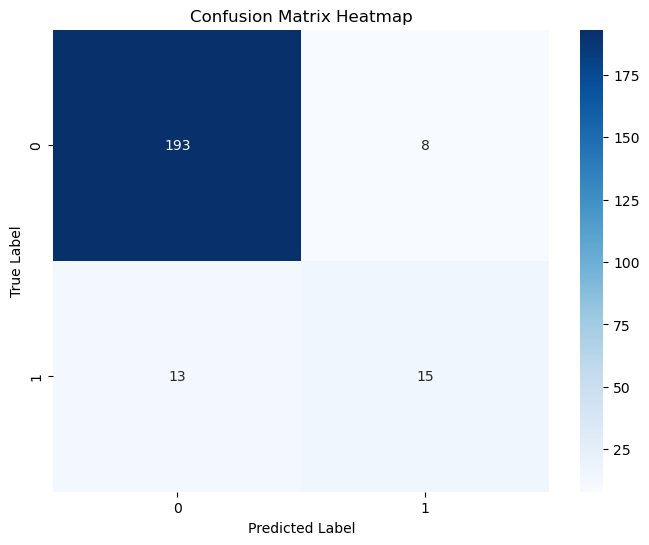

In [7]:
# --- 필요한 라이브러리 모두 불러오기 ---
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

# --- 1. 데이터 준비 및 모델 학습/예측 ---
# 데이터를 불러옵니다. (Part4 Chapter8 Wine Quality.csv 파일이 코드와 같은 폴더에 있어야 합니다)
df = pd.read_csv("Part4 Chapter8 Wine Quality.csv")

# 타깃 변수 ‘good_quality’를 생성합니다. (7점 이상이면 1, 아니면 0)
df['good_quality'] = (df['quality'] >= 7).astype(int)

# 피처(X)와 타깃(y)을 정의합니다.
X = df.drop(columns=['quality', 'good_quality'])
y = df['good_quality']

# 데이터를 훈련용과 테스트용으로 분할합니다.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 피처 데이터를 표준화 스케일링합니다.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 로지스틱 회귀 모델을 생성하고 학습시킵니다.
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# 테스트 데이터로 예측을 수행합니다.
predictions = model.predict(X_test_scaled)

# --- 2. 오차 행렬 계산 및 히트맵 시각화 ---
# 오차 행렬을 계산합니다.
cm = confusion_matrix(y_test, predictions)

# heatmap을 사용해 오차 행렬을 시각화합니다.
plt.figure(figsize=(8, 6)) # 그래프 크기를 보기 좋게 설정합니다.
sns.heatmap(cm, 
    annot=True, # annot=True: 각 칸에 숫자 값을 표시합니다.
    fmt='d', # fmt=‘d’: 숫자를 정수(decimal) 형태로 표현합니다.
    cmap='Blues') # cmap=‘Blues’: 색상 테마를 파란색 계열로 지정합니다.

# 그래프의 x축, y축, 제목을 설정하여 이해를 돕습니다.
plt.xlabel('Predicted Label') # x축 라벨
plt.ylabel('True Label') # y축 라벨
plt.title('Confusion Matrix Heatmap') # 그래프 제목
plt.show() # 그래프를 화면에 출력합니다.

## 08 · ROC 곡선과 AUC
교재 **221쪽**

AUC Score: 0.9010


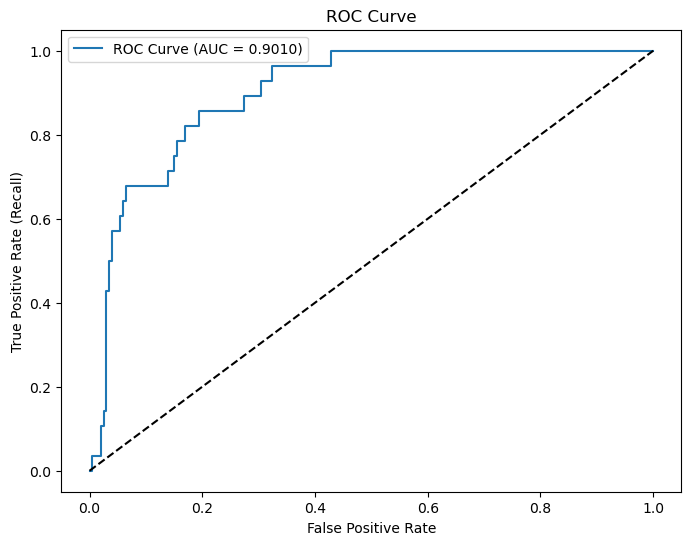

In [8]:
# ROC 커브와 AUC 스코어 계산을 위해 라이브러리를 불러옵니다.
from sklearn.metrics import roc_curve, roc_auc_score

# 1. ‘좋은 와인(1)’일 확률 예측: predict_proba는 각 클래스에 대한 확률을 반환합니다.
# [:, 1]을 사용하여 ‘좋은 와인(1)’일 확률만 선택합니다.
predictions_prob = model.predict_proba(X_test_scaled)[:, 1]

# 2. ROC 곡선 계산: roc_curve 함수는 다양한 컷오프 점수(thresholds)에 대한
# FPR(False Positive Rate)과 TPR(True Positive Rate)을 계산해 줍니다.
fpr, tpr, thresholds = roc_curve(y_test, predictions_prob)

# 3. AUC 스코어 계산: roc_auc_score 함수로 곡선 아래 면적을 구합니다.
auc = roc_auc_score(y_test, predictions_prob)
print(f'AUC Score: {auc:.4f}')

# 4. ROC Curve 시각화
plt.figure(figsize=(8, 6)) # 그래프 크기를 설정합니다.

# plot 함수로 x축에는 fpr, y축에는 tpr 값을 넣어 곡선을 그립니다.
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.4f})')

# 참고용 대각선: 완전히 무작위로 예측하는 모델의 성능을 나타냅니다.
plt.plot([0, 1], [0, 1], 'k--')

# 축과 제목, 범례를 추가하여 그래프의 가독성을 높입니다.
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.show()